n   Analytical   Numerical
1 2.4674 2.46735
2 9.8696 9.8688
3 22.20661 22.20254


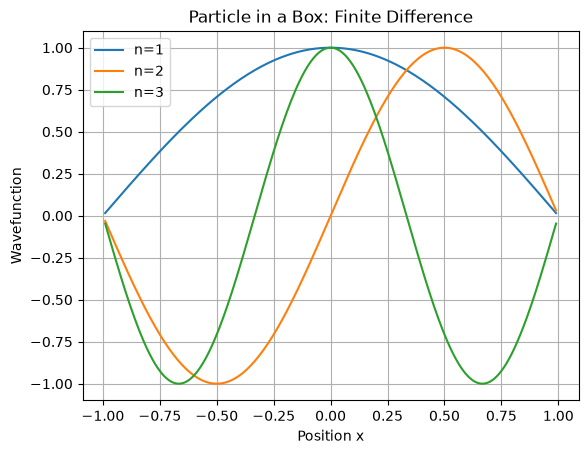

In [2]:

import numpy as np
import matplotlib.pyplot as plt

a = 1.0
N = 200
dx = 2*a/(N+1)
x = np.linspace(-a+dx, a-dx, N)

# Hamiltonian matrix
H = np.diag(np.full(N, 2/dx**2))
H += np.diag(np.full(N-1, -1/dx**2), 1)
H += np.diag(np.full(N-1, -1/dx**2), -1)

E, psi = np.linalg.eigh(H)

print("n   Analytical   Numerical")
for n in range(1, 4):
    exact = n**2*np.pi**2/(4*a**2)
    print(n, round(exact, 5), round(E[n-1], 5))

# Plot first three eigenfunctions
for n in range(3):
    y = psi[:, n]
    y = y / np.sqrt(np.sum(y**2)*dx)
    plt.plot(x, y, label=f"n={n+1}")

plt.xlabel("Position x")
plt.ylabel("Wavefunction")
plt.title("Particle in a Box: Finite Difference")
plt.legend()
plt.grid()
plt.show()



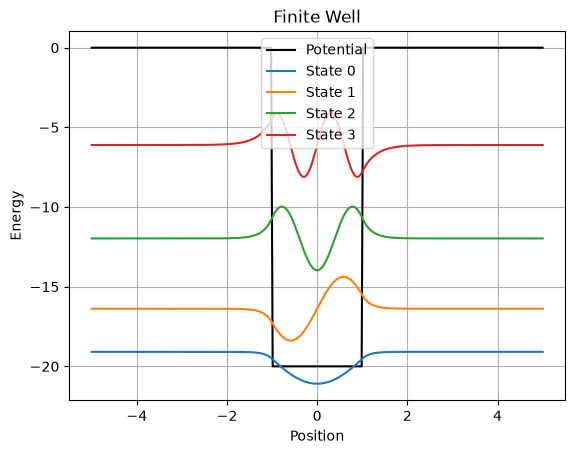

Energy eigenvalues:
[-19.08887265 -16.38146327 -11.97169695  -6.10892748  -0.0662217 ]


In [3]:
# Finite square well potential

import numpy as np
import matplotlib.pyplot as plt

N = 300
L = 5
a = 1
V0 = 20

x = np.linspace(-L, L, N)
dx = x[1] - x[0]

V = np.zeros(N)
V[np.abs(x) < a] = -V0

# Hamiltonian matrix
H = np.diag(1/dx**2 + V[1:-1])
H += np.diag(-0.5/dx**2*np.ones(N-3), 1)
H += np.diag(-0.5/dx**2*np.ones(N-3), -1)

# Eigenvalues and eigenfunctions
E, psi = np.linalg.eigh(H)

# Plot
plt.plot(x, V, 'k', label='Potential')

for i in range(4):
    if E[i] < 0:
        wave = np.zeros(N)
        wave[1:-1] = psi[:, i]
        plt.plot(x, E[i] + 2*wave/np.max(np.abs(wave)),
                 label='State '+str(i))

plt.xlabel('Position')
plt.ylabel('Energy')
plt.title('Finite Well')
plt.legend()
plt.grid()
plt.show()

print("Energy eigenvalues:")
print(E[E < 0])



Numerical and Analytical Energies
0 0.4999496599236509 0.5
1 1.4997482793347838 1.5
2 2.499345467426904 2.5
3 3.498741163341617 3.5
4 4.497935307150526 4.5


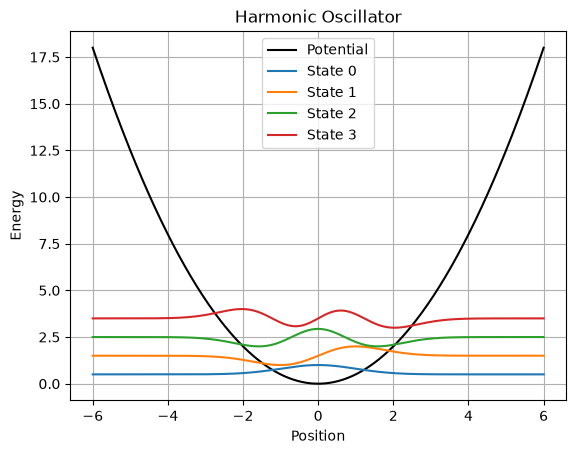

In [5]:

import numpy as np
import matplotlib.pyplot as plt

N = 300
L = 6

x = np.linspace(-L, L, N)
dx = x[1]-x[0]

V = 0.5*x**2

# Hamiltonian matrix
H = np.diag(1/dx**2 + V[1:-1])
H += np.diag(-0.5/dx**2*np.ones(N-3), 1)
H += np.diag(-0.5/dx**2*np.ones(N-3), -1)

# Eigenvalues and eigenfunctions
E, psi = np.linalg.eigh(H)

print("Numerical and Analytical Energies")

for n in range(5):
    print(n, E[n], n+0.5)

# Plot
plt.plot(x, V, 'k', label='Potential')

for i in range(4):
    wave = np.zeros(N)
    wave[1:-1] = psi[:, i]

    plt.plot(x, E[i]+0.5*wave/np.max(np.abs(wave)),
             label='State '+str(i))

plt.xlabel('Position')
plt.ylabel('Energy')
plt.title('Harmonic Oscillator')
plt.legend()
plt.grid()
plt.show()
